# Recherches évolutionnaires en parallèle — comparer plusieurs réglages

Lance **plusieurs recherches en même temps**, une par processus (une par cœur), avec les mêmes paramètres communs
et quelques réglages qui changent d'une course à l'autre. Fitness par courbes de désirabilité
(`scripts/Lea/fitness_functions.py`).

Deux options utiles pour ces comparaisons :
- `unique_kekule` : un seul SMILES par molécule aromatique (désactivé par défaut : plus lent, sans gain d'exploration mesuré, R21–R25) ;
- `remember_invalid` : ne pas réévaluer les SMILES déjà jugés invalides (activé par défaut, même recherche en moins de temps, R19) ou tout réévaluer.

Code : `scripts/Lea/parallel_search.py`. Résultats : `output/<NOM_EXPERIENCE>/<course>/`.

1. Imports — 2. Paramètres communs — 3. Les courses — 4. Lancement — 5. Résultats — 6. Meilleures molécules

In [8]:
import os, sys
from pathlib import Path

# racine du projet = premier dossier parent qui contient evomol/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
for p in (ROOT, ROOT / "scripts", ROOT / "scripts" / "Lea"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
os.chdir(ROOT)  # les filtres ChEMBL/ZINC lisent external_data/ en relatif

import matplotlib.pyplot as plt
from IPython.display import display
from rdkit.Chem import Draw, MolFromSmiles

import fitness_functions as ff      # importé par son nom : les courbes passent aux processus
import parallel_search as ps
Sigmoid, Gaussian = ff.Sigmoid, ff.Gaussian

print(f"Imports OK — {os.cpu_count()} cœurs disponibles")

Imports OK — 8 cœurs disponibles


## 2. Paramètres communs

Valeurs utilisées par **toutes** les courses, sauf si une course les remplace en § 3.

In [9]:
# ── Molécule de départ et espace chimique ───────────────────────────────────
SMILES_DEPART   = "c1ccccc1"        # benzène
#   SMILES quelconque : molécule d'où part la recherche (doit passer les filtres).
ACCEPTED_ATOMS  = ["C", "O", "N"]
#   éléments autorisés dans les molécules générées.
MAX_HEAVY_ATOMS = 1_000_000
#   entier >= 1 : nb max d'atomes lourds. 1_000_000 = pas de limite : seule la courbe sur
#   n_heavy_atoms (fitness_goals) règle la taille.

# ── Arrêt de la recherche ───────────────────────────────────────────────────
MAX_GENERATIONS = 10**9
MAX_TIME_SEC    = 200       # durée de chaque course, en secondes

# ── Population et sélection ─────────────────────────────────────────────────
POPULATION_SIZE = 100
#   entier >= 1 : nb de molécules gardées.
NB_REPLACEMENTS = 10
#   entier, 1 <= NB_REPLACEMENTS <= POPULATION_SIZE : nb de pires molécules remplacées par génération.
SELECTION       = "best"
#   "best" : de la meilleure à la pire ; "random" : ordre aléatoire ; "roulette" : tirage pondéré par la fitness.
SEED            = 42
#   entier : recherche reproductible ; None : différente à chaque exécution.

# ── Mutation ────────────────────────────────────────────────────────────────
DEPTH                = 2
#   entier >= 1 : nb (max) d'actions appliquées à la suite dans une mutation.
RANDOM_DEPTH         = True
#   True : nb d'actions tiré entre 1 et DEPTH ; False : exactement DEPTH actions.
NB_MAX_TRIES         = 50
#   entier >= 1 : nb de mutants essayés par parent avant de passer au parent suivant.
UNIFORM_OVER_ACTIONS = False
#   False : on tire d'abord un type d'action, puis une action de ce type.
#   True  : tirage uniforme sur toutes les actions possibles (ignore PRESELECT_ACTIONS).
PRESELECT_ACTIONS    = True
#   True : ne liste que les actions du type tiré (rapide) ; False : liste tout avant de tirer.

# ── Espace d'action ─────────────────────────────────────────────────────────
INSERT_CARBON           = True
#   True : InsertCarbonMG disponible ; False : retiré.
AVOID_SP3_ON_SP3        = True
#   True : AddAtomMG ne greffe pas de C sp3 sur un C sp3.
ADD_ATOM_MULTIPLE_BONDS = False
#   True : AddAtomMG peut greffer par double ou triple liaison (=CH2, =O, #N…).
AVOID_BOND_BREAKING     = False
#   True : ChangeBondMG ne supprime jamais de liaison.
AVOID_BOND_FORMING      = False
#   True : ChangeBondMG ne crée jamais de liaison.
WITH_ADD_GROUP          = False
#   True : ajoute AddGroupMG.
WITH_REMOVE_GROUP       = False
#   True : ajoute RemoveGroupMG.

# ── Filtres ── appliqués dans cet ordre : Hückel → sp3 → ChEMBL/ZINC → Hetero
FILTER_HUCKEL  = True
#   True / False : compatibilité Hückel (tout C sp3 doit être en bout de chaîne).
MAX_SP3        = None
#   None : filtre inactif ; entier >= 0 : nb max d'atomes sans liaison π.
FILTER_REALISM = "chembl_zinc"
#   "chembl_zinc" (le plus large), "chembl" (plus restrictif) ou None (aucun filtre de réalisme).
FILTER_HETERO  = False
#   True / False : chaînes d'hétéroatomes (HeteroatomChainFilter).
MAX_RING_N     = 3
#   nb max d'azotes en cycle (si FILTER_HETERO).

# ── Options de comparaison ──────────────────────────────────────────────────
UNIQUE_KEKULE = False
#   False : SMILES kékulé tel que produit par la mutation (une molécule aromatique peut avoir
#           deux SMILES ; défaut, le plus rapide).
#   True  : un seul SMILES par molécule (plus de doublons, ~15–30 % de candidats/s en moins).
REMEMBER_INVALID = True
#   True  : les SMILES déjà jugés invalides ne sont pas réévalués (même recherche, plus rapide).
#   False : chaque candidat est réévalué.

# ── Objectifs de fitness : (nom_propriété, courbe, poids) ─────────────────────
# Courbes (score entre 0 et 1) : Sigmoid(center, steepness, "up"/"down"), Gaussian(center, sigma),
# produit de courbes. Propriétés : "huckel_gap_lambda", "huckel_homo_lambda", "huckel_lumo_lambda",
# "n_heavy_atoms", "mol_weight", "SAScore", "QED", "logP", "CycleScore", "PLogP"…
fitness_goals = [
    ("huckel_homo_lambda", Gaussian(center=0.4, sigma=0.15), 1),                     # λ HOMO proche de 0.4
    ("n_heavy_atoms",      Gaussian(center=70, sigma=30), 3),                        # ~70 atomes lourds
]
AGGREGATION = "sum"
#   "sum" : Σ poids·score / Σ poids ; "geometric" : ∏ score^(poids/Σ poids).

# ── Sauvegarde ──────────────────────────────────────────────────────────────
NOM_EXPERIENCE     = "parallele_kekule_memoire"
#   résultats dans output/<NOM_EXPERIENCE>/<course>/
SAVE_N_GENERATIONS = 0
#   entier >= 0 : sauver la population toutes les N générations (0 : jamais).
HISTORIQUE_TOUTES  = 10
#   garder les valeurs de la population toutes les N générations (tracés).

COMMON = dict(
    start_smiles=SMILES_DEPART, accepted_atoms=ACCEPTED_ATOMS, max_heavy_atoms=MAX_HEAVY_ATOMS,
    max_generations=MAX_GENERATIONS, max_time=MAX_TIME_SEC,
    population_size=POPULATION_SIZE, nb_replacements=NB_REPLACEMENTS, selection=SELECTION,
    random_seed=SEED,
    depth=DEPTH, random_depth=RANDOM_DEPTH, nb_max_tries=NB_MAX_TRIES,
    uniform_over_actions=UNIFORM_OVER_ACTIONS, preselect_actions=PRESELECT_ACTIONS,
    insert_carbon=INSERT_CARBON, avoid_sp3_on_sp3=AVOID_SP3_ON_SP3,
    add_atom_multiple_bonds=ADD_ATOM_MULTIPLE_BONDS,
    avoid_bond_breaking=AVOID_BOND_BREAKING, avoid_bond_forming=AVOID_BOND_FORMING,
    with_add_group=WITH_ADD_GROUP, with_remove_group=WITH_REMOVE_GROUP,
    huckel=FILTER_HUCKEL, max_sp3=MAX_SP3, realism=FILTER_REALISM,
    hetero=FILTER_HETERO, max_ring_n=MAX_RING_N,
    save_n_generations=SAVE_N_GENERATIONS,
    unique_kekule=UNIQUE_KEKULE, remember_invalid=REMEMBER_INVALID,
)
ff.check_goals(fitness_goals, AGGREGATION)
print(f"Départ : {SMILES_DEPART}  —  {MAX_TIME_SEC}s par course  —  agrégation {AGGREGATION}")
for name, curve, w in fitness_goals:
    print(f"  {name:<22} poids {w:<4g} {curve!r}")

Départ : c1ccccc1  —  200s par course  —  agrégation sum
  huckel_homo_lambda     poids 1    Gaussian(center=0.4, sigma=0.15)
  n_heavy_atoms          poids 3    Gaussian(center=70, sigma=30)


## 3. Les courses

Une entrée par course : `"nom": {paramètre: valeur, …}`. Seuls les paramètres qui **changent** par rapport au § 2
sont à écrire ; tout paramètre du dictionnaire `COMMON` peut être remplacé
(ex. `"unique_kekule"`, `"remember_invalid"`, `"random_seed"`, `"max_sp3"`, `"realism"`, `"depth"`, `"start_smiles"`…).
Une course par cœur au plus : au-delà, les courses se partagent les cœurs et les temps ne sont plus comparables.

In [10]:
RUNS = {
    "kekule_ancien__sans_memoire": {"unique_kekule": False, "remember_invalid": False},
    "kekule_ancien__avec_memoire": {"unique_kekule": False, "remember_invalid": True},
    "kekule_unique__sans_memoire": {"unique_kekule": True,   "remember_invalid": False},
    "kekule_unique__avec_memoire": {"unique_kekule": True,   "remember_invalid": True},
}

# Exemples d'autres comparaisons :
# RUNS = {f"graine_{s}": {"random_seed": s} for s in (1, 2, 3, 4)}
# RUNS = {"sp3_libre": {}, "sp3_max_3": {"max_sp3": 3}, "sans_realisme": {"realism": None},
#         "chembl_seul": {"realism": "chembl"}}

for name, overrides in RUNS.items():
    unknown = set(overrides) - set(COMMON)
    if unknown:
        raise ValueError(f"{name} : paramètres inconnus {sorted(unknown)}")
    print(f"{name:<32} {overrides}")
if len(RUNS) > os.cpu_count():
    print(f"ATTENTION : {len(RUNS)} courses pour {os.cpu_count()} cœurs")

kekule_ancien__sans_memoire      {'kekule_unique': False, 'memoire': False}
kekule_ancien__avec_memoire      {'kekule_unique': False, 'memoire': True}
kekule_unique__sans_memoire      {'kekule_unique': True, 'memoire': False}
kekule_unique__avec_memoire      {'kekule_unique': True, 'memoire': True}


## 4. Lancement

Les courses tournent en même temps ; la cellule rend la main quand toutes sont finies (≈ `MAX_TIME_SEC`).
Chaque course écrit son propre journal DEBUG : `output/<NOM_EXPERIENCE>/<course>/evomol.log`.

In [11]:
OUTPUT_DIR = ROOT / "output" / NOM_EXPERIENCE
print(f"Démarrage de {len(RUNS)} courses de {MAX_TIME_SEC}s → {OUTPUT_DIR}")
results = ps.run_parallel(COMMON, RUNS, fitness_goals, AGGREGATION, OUTPUT_DIR,
                          history_every=HISTORIQUE_TOUTES)
print("Terminé.")

Démarrage de 4 courses de 200s → /Users/LeaClautour/Desktop/HuckMol-2.0/output/parallele_kekule_memoire
Terminé.


## 5. Résultats

Pour relire une expérience déjà faite sans la relancer : `results = ps.load_results(ROOT / "output" / "nom")`.

course                       générations  candidats/s  évaluations  rejets mémoire  meilleure fitness  fitness moyenne  atomes moyens  molécules distinctes
-----------------------------------------------------------------------------------------------------------------------------------------------------------
kekule_ancien__sans_memoire          124          834       151616               0             0.5226           0.5036           26.4                   100
kekule_ancien__avec_memoire          147          922        93034           75969             0.5683           0.5475           29.4                   100
kekule_unique__sans_memoire           72          656       124833               0             0.4892           0.4654           22.9                   100
kekule_unique__avec_memoire           74          739        76226           64129             0.4892           0.4673           23.0                   100


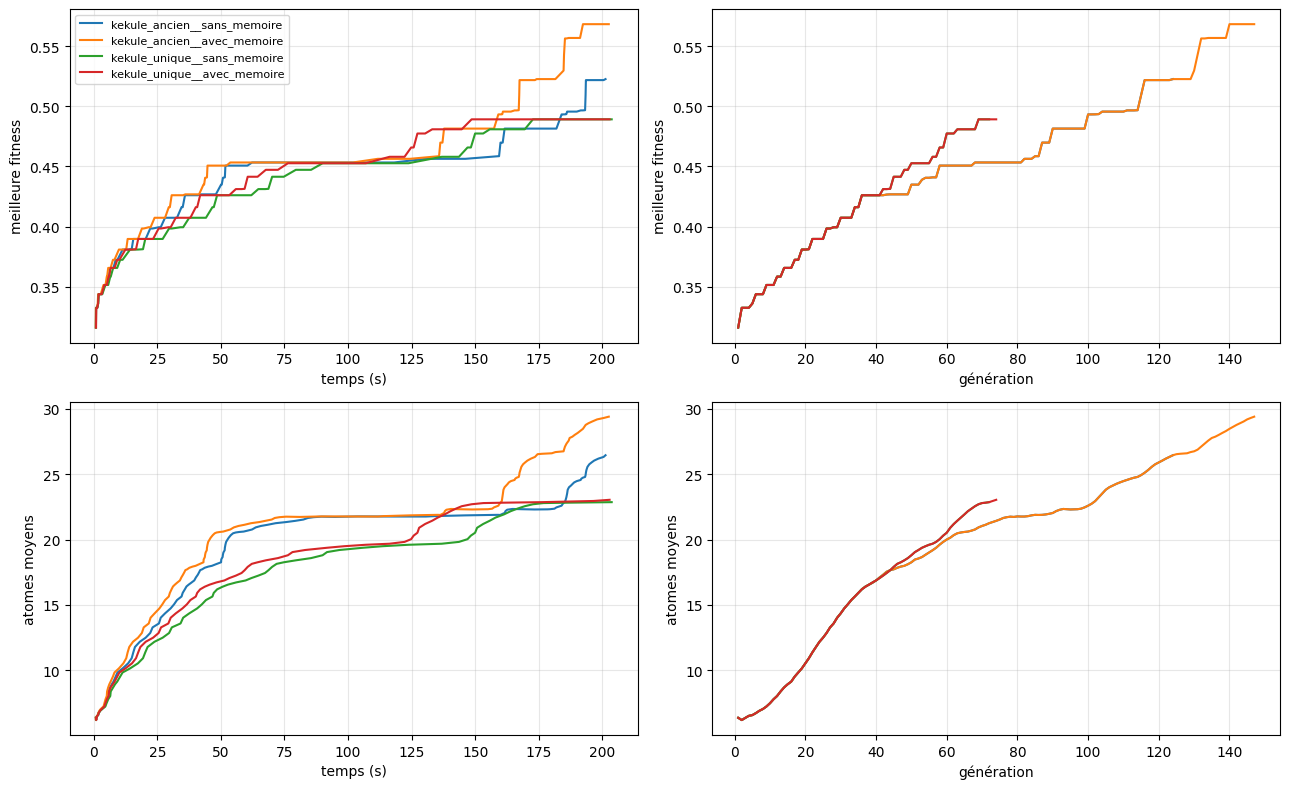

In [12]:
print(ps.summary_table(results))
fig = ps.plot_trajectories(results)
plt.show()

## 6. Meilleures molécules de chaque course

── kekule_ancien__sans_memoire ── meilleure fitness 0.5226, 124 générations, 26.4 atomes en moyenne


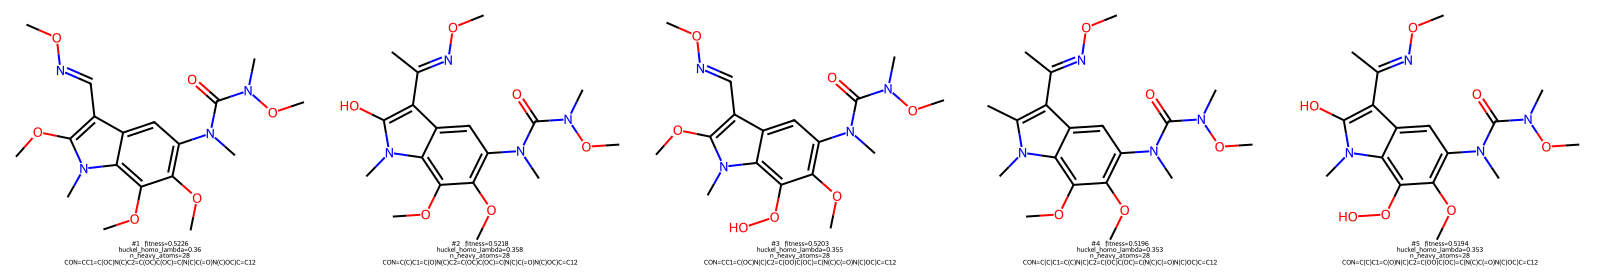

── kekule_ancien__avec_memoire ── meilleure fitness 0.5683, 147 générations, 29.4 atomes en moyenne


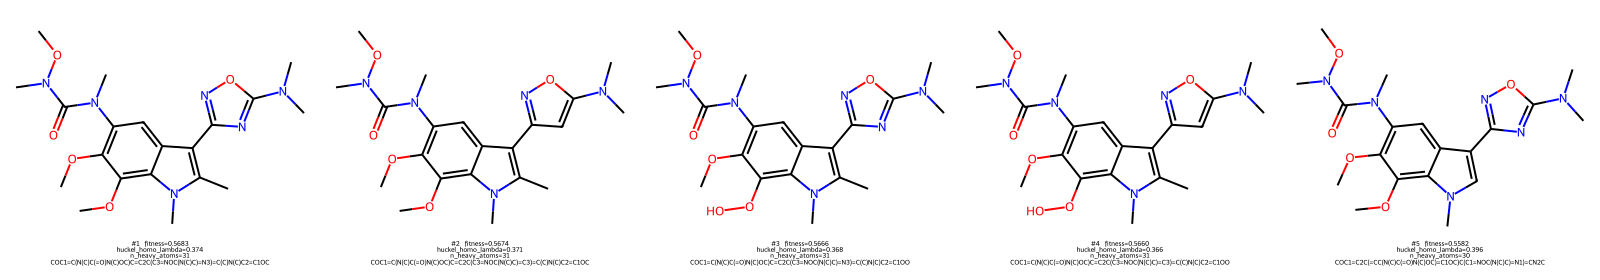

── kekule_unique__sans_memoire ── meilleure fitness 0.4892, 72 générations, 22.9 atomes en moyenne


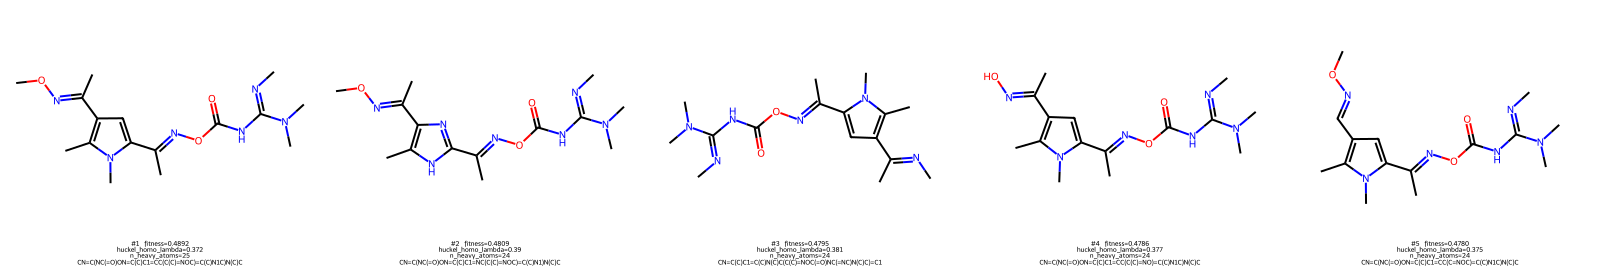

── kekule_unique__avec_memoire ── meilleure fitness 0.4892, 74 générations, 23.0 atomes en moyenne


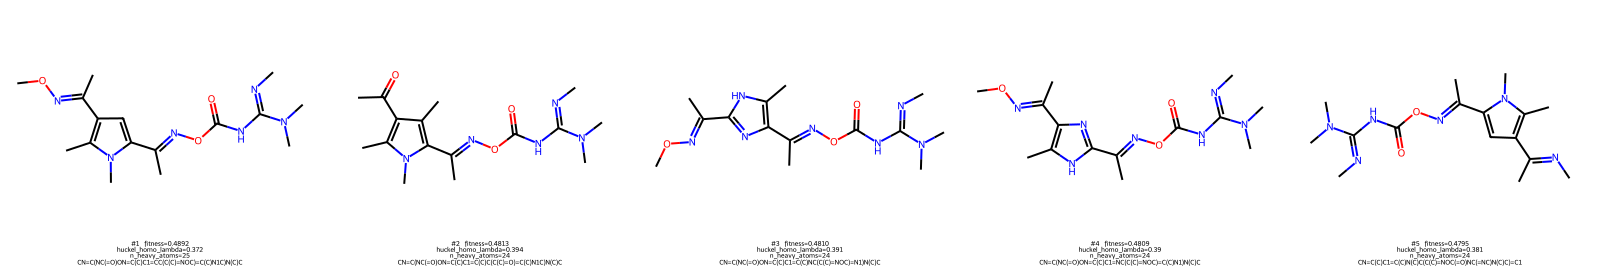

In [13]:
TOP_N = 5
for name, r in results.items():
    top = r["top"][:TOP_N]
    mols = [MolFromSmiles(m["smiles"]) for m in top]
    legends = [f"#{i}  fitness={m['fitness']:.4f}\n"
               + "\n".join(f"{g}={m[g]:.3g}" for g, *_ in fitness_goals) + f"\n{m['smiles']}"
               for i, m in enumerate(top, start=1)]
    print(f"── {name} ── meilleure fitness {r['meilleure_fitness']:.4f}, "
          f"{r['generations']} générations, {r['atomes_moyen']:.1f} atomes en moyenne")
    display(Draw.MolsToGridImage(mols, molsPerRow=TOP_N, subImgSize=(320, 280), legends=legends))